# Credit Risk Prediction — Previsão de Inadimplência

**Projeto de portfólio em Ciência de Dados (versão 1.0)**  
**Objetivo:** investigar padrões de comportamento financeiro e comparar modelos de classificação capazes de estimar inadimplência na fatura do mês seguinte.

**Base:** *Default of Credit Card Clients* — UCI Machine Learning Repository (`id=350`), com 30.000 observações.  
**Ferramentas:** Python, Pandas, Matplotlib e Scikit-learn.  
**Escopo:** exercício educacional; **não é um sistema para decisões reais de concessão de crédito**.

**Como executar:** no Google Colab, utilize **Ambiente de execução → Executar tudo**. A obtenção dos dados requer conexão com a internet.

## 1. Carregamento e compreensão da base

A variável **`Y`** indica inadimplência no mês seguinte (`0` = não; `1` = sim). O identificador **`ID`** é usado apenas para identificar registros, não como característica de previsão.

Exemplos de variáveis:
- `X1`: limite de crédito; `X5`: idade.
- `X2`, `X3`, `X4`: características demográficas e categóricas.
- `X6`–`X11`: histórico de pagamentos; `X12`–`X17`: valores das faturas; `X18`–`X23`: pagamentos anteriores.

Os valores monetários estão em **novos dólares taiwaneses (NT$)**. A coleta é histórica (2005, Taiwan), portanto não se deve generalizar automaticamente para clientes atuais ou brasileiros.

In [ ]:
%pip install -q ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
dados =fetch_ucirepo(id=350)
tabela = dados.data.original

In [ ]:
tabela.head()

,ID,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
tabela.shape

(30000, 25)

### 1.1 Distribuição das classes

Como o grupo `Y=1` é minoritário, **acurácia isolada pode enganar**: um classificador que sempre previsse `0` acertaria 77,88% dos registros desta base.

In [ ]:

tabela['Y'].value_counts()


,count
Y,
0,23364
1,6636


In [ ]:

tabela['Y'].value_counts(normalize=True) * 100


,proportion
Y,
0,77.88
1,22.12


## 2. Análise exploratória (EDA)

Vamos investigar se variáveis como idade e histórico de pagamentos estão **associadas** à inadimplência. Associação estatística **não comprova causalidade**.

In [ ]:

tabela.groupby('Y')['X5'].mean().round(2)


,X5
Y,
0,35.42
1,35.73


In [ ]:

import matplotlib.pyplot as plt


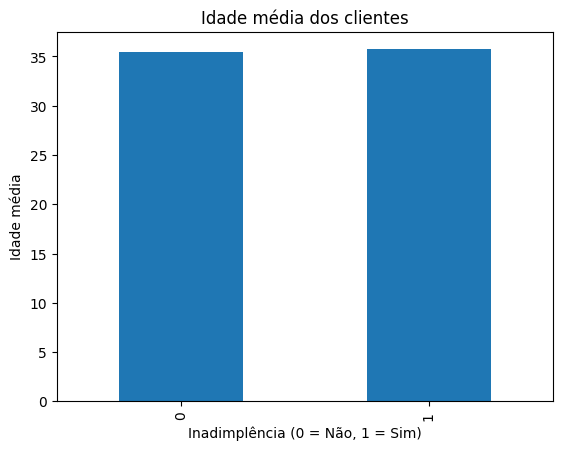

In [ ]:

medias = tabela.groupby('Y')['X5'].mean()

medias.plot(kind='bar')

plt.title('Idade média dos clientes')
plt.xlabel('Inadimplência (0 = Não, 1 = Sim)')
plt.ylabel('Idade média')
plt.show()


**Interpretação:** na amostra, as idades médias são muito próximas (aproximadamente 35,42 e 35,73 anos). Essa diferença descritiva, isoladamente, não permite concluir que idade seja um fator causal.

## 3. Qualidade e tratamento dos dados

Verificações iniciais: valores ausentes, linhas duplicadas e quantidade de IDs distintos. A ausência de valores nulos **não garante** que a base esteja livre de problemas semânticos.

In [24]:

tabela.isnull().sum().sum()


np.int64(0)

In [25]:

tabela.duplicated().sum()


np.int64(0)

In [26]:

tabela['ID'].nunique()


30000

### 3.1 Padronização da escolaridade (`X3`)

A documentação descreve os códigos `1` a `4`, enquanto a base contém também `0`, `5` e `6`. Neste estudo, vamos **agrupar `5` e `6` em `0`**, interpretando `0` como **categoria não documentada/desconhecida**, sem excluir observações. Esse agrupamento é uma decisão de pré-processamento, não uma informação confirmada sobre a escolaridade das pessoas.

In [27]:

tabela['X3'].value_counts().sort_index()


,count
X3,
0,14
1,10585
2,14030
3,4917
4,123
5,280
6,51


In [28]:

tabela_limpa = tabela.copy()


In [29]:

tabela_limpa['X3'] = tabela_limpa['X3'].replace({
    5: 0,
    6: 0
})


In [30]:

tabela_limpa['X3'].value_counts().sort_index()


,count
X3,
0,345
1,10585
2,14030
3,4917
4,123


### 3.2 Estado civil (`X4`)

O código `0` aparece em 54 registros e será **mantido como categoria não documentada**. Não o converteremos em outro estado civil sem evidência.

In [32]:
tabela_limpa['X4'].value_counts().sort_index()

,count
X4,
0,54
1,13659
2,15964
3,323


### 3.3 Histórico de pagamentos e inadimplência

A variável `X6` descreve a situação recente de pagamento. Códigos positivos sinalizam atraso; códigos especiais (`-2`, `-1` e `0`) pedem cautela de interpretação. Para evitar conclusões frágeis, analisamos a **taxa de inadimplência junto com o tamanho de cada grupo**.

In [34]:

resumo = tabela_limpa.groupby('X6')['Y'].agg(['count', 'mean'])

resumo['mean'] = (resumo['mean'] * 100).round(2)

resumo


,count,mean
X6,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55


**Interpretação:** grupos com atrasos de dois ou três meses registraram taxas maiores de inadimplência. Categorias com poucos clientes (por exemplo, 7 meses de atraso, com 9 observações) têm estimativas percentuais mais instáveis.

## 4. Preparação para Machine Learning

Dividimos a amostra em treino (19.200), validação (4.800) e teste separado (6.000), por amostragem estratificada. Retiramos `ID` e `Y` das características de entrada (`X`).

- **Treino:** o algoritmo aprende padrões.
- **Validação:** comparamos algoritmos e limiares.
- **Teste:** seria usado apenas para avaliação final independente.

**Nota de transparência:** no histórico original deste trabalho, o conjunto de teste **já foi examinado** em uma primeira experiência com Regressão Logística. Por isso, não tratamos esse teste como avaliação final rigorosamente intocada. Este notebook organizado prioriza a **comparação de modelos na validação** e não reivindica desempenho independente de produção.

In [37]:

X = tabela_limpa.drop(columns=['ID', 'Y'])

y = tabela_limpa['Y']


In [38]:

from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [39]:

print("Dados de treino:", X_treino.shape)

print("Dados de teste:", X_teste.shape)


Dados de treino: (24000, 23)
Dados de teste: (6000, 23)


In [45]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_treino,
    y_treino,
    test_size=0.2,
    random_state=42,
    stratify=y_treino
)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)


Treinamento: (19200, 23)
Validação: (4800, 23)


## 5. Treinamento dos modelos

Comparamos **Random Forest** e **Regressão Logística** nos mesmos dados de treino e validação. Para `X2`, `X3` e `X4` aplicamos *One-Hot Encoding*. Para a Regressão Logística, padronizamos também as variáveis numéricas. Os pré-processamentos ficam dentro dos *pipelines*, que ajustam suas transformações apenas durante o treino.

**Observação:** o histórico de pagamentos contém valores especiais cuja interpretação e codificação podem ser aprimoradas em estudos futuros.

### 5.1 Random Forest

In [46]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

colunas_categoricas = ['X2', 'X3', 'X4']

preparacao = ColumnTransformer(
    transformers=[
        ('categorias',
         OneHotEncoder(handle_unknown='ignore'),
         colunas_categoricas)
    ],
    remainder='passthrough'
)


In [47]:

modelo_floresta = Pipeline([
    ('preparacao', preparacao),
    ('modelo', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

modelo_floresta.fit(X_train, y_train)


Pipeline(steps=[('preparacao',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorias',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['X2', 'X3', 'X4'])])),
                ('modelo',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [48]:

previsoes_floresta = modelo_floresta.predict(X_val)

print(classification_report(
    y_val,
    previsoes_floresta
))




              precision    recall  f1-score   support

           0       0.84      0.94      0.89      3738
           1       0.65      0.38      0.48      1062

    accuracy                           0.82      4800
   macro avg       0.75      0.66      0.68      4800
weighted avg       0.80      0.82      0.80      4800



### 5.2 Regressão Logística

In [49]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

categoricas = ['X2', 'X3', 'X4']

numericas = X_train.columns.difference(categoricas).tolist()

preparacao_logistica = ColumnTransformer([
    ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas),
    ('numericas', StandardScaler(), numericas)
])

modelo_logistico = Pipeline([
    ('preparacao', preparacao_logistica),
    ('modelo', LogisticRegression(max_iter=2000))
])

modelo_logistico.fit(X_train, y_train)


Pipeline(steps=[('preparacao',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['X2', 'X3', 'X4']),
                                                 ('numericas', StandardScaler(),
                                                  ['X1', 'X10', 'X11', 'X12',
                                                   'X13', 'X14', 'X15', 'X16',
                                                   'X17', 'X18', 'X19', 'X20',
                                                   'X21', 'X22', 'X23', 'X5',
                                                   'X6', 'X7', 'X8', 'X9'])])),
                ('modelo', LogisticRegression(max_iter=2000))])

In [50]:

previsoes_logistica = modelo_logistico.predict(X_val)

print(classification_report(
    y_val,
    previsoes_logistica
))


              precision    recall  f1-score   support

           0       0.82      0.97      0.89      3738
           1       0.71      0.26      0.38      1062

    accuracy                           0.81      4800
   macro avg       0.76      0.62      0.64      4800
weighted avg       0.80      0.81      0.78      4800



### 5.3 Comparação dos modelos (classe 1 = inadimplente)

Valores observados na validação de 4.800 clientes (arredondados):

| Modelo | Acurácia | Precisão (classe 1) | Recall (classe 1) | F1 (classe 1) |
|:--|--:|--:|--:|--:|
| Regressão Logística | 81% | 71% | 26% | 38% |
| Random Forest | 82% | 65% | 38% | 48% |

O **Random Forest** apresentou melhor recall e F1 para a classe 1; já a Regressão Logística apresentou maior precisão nessa classe. A melhor escolha depende também dos custos dos falsos positivos e negativos.

## 6. Teste de limiar no Random Forest

A previsão padrão usa limiar `0,50`. Avaliamos `0,30`, `0,40` e `0,50` **no conjunto de validação**, buscando um equilíbrio entre capturar inadimplentes e evitar falsos alarmes.

In [51]:

from sklearn.metrics import precision_score, recall_score, f1_score

probabilidades = modelo_floresta.predict_proba(X_val)[:, 1]

for limite in [0.30, 0.40, 0.50]:

    previsoes = (probabilidades >= limite).astype(int)

    precision = precision_score(y_val, previsoes)
    recall = recall_score(y_val, previsoes)
    f1 = f1_score(y_val, previsoes)

    print(f"Limiar: {limite}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-score: {f1:.2f}")
    print("--------------------")


Limiar: 0.3
Precision: 0.51
Recall: 0.56
F1-score: 0.54
--------------------
Limiar: 0.4
Precision: 0.60
Recall: 0.47
F1-score: 0.53
--------------------
Limiar: 0.5
Precision: 0.65
Recall: 0.38
F1-score: 0.48
--------------------


### 6.1 Resultado do estudo de limiar

| Limiar | Precisão (classe 1) | Recall (classe 1) | F1 (classe 1) |
|--:|--:|--:|--:|
| **0,30** | 51% | **56%** | **54%** |
| 0,40 | 60% | 47% | 53% |
| 0,50 | 65% | 38% | 48% |

O limiar **0,30** teve o maior F1 entre os três valores experimentados, mas aumentou o risco de falsos positivos. A escolha é **exploratória**, não uma configuração validada para uso real.

## 7. Conclusão e limitações

Este projeto praticou coleta de dados públicos, EDA, verificação de qualidade, tratamento de categorias, separação de amostras, treinamento em *pipelines*, comparação de algoritmos e avaliação do limiar de decisão.

**Principal aprendizado:** acurácia de 81–82% não é suficiente para avaliar um modelo de inadimplência. O recall da classe 1 revelou que muitos casos passaram despercebidos. No conjunto de validação, o Random Forest com limiar 0,30 atingiu recall de **56%** e F1 de **54%**, com precisão de **51%**.

**Limitações importantes:**
1. Os dados são históricos e de Taiwan, não representando diretamente a população atual.
2. O conjunto de teste já foi consultado em experimentos anteriores: **não há avaliação final independente intocada nesta versão**.
3. Não foram avaliados calibração probabilística, incerteza das métricas, custos operacionais ou imparcialidade entre grupos.
4. Variáveis demográficas podem levantar questões de viés e discriminação; o uso real exigiria auditorias e critérios regulatórios adequados.

**Próximas melhorias (opcionais):** obter uma nova amostra de teste independente, avaliar PR-AUC, calibrar probabilidades, investigar estabilidade temporal e realizar análises de equidade. **A versão 1.0 se encerra aqui.**